# Audio File and Definitions

In [97]:
from pathlib import Path

import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

In [4]:
AUDIO_PATH = Path("4rd_sanctuary.mp3")

audio, sample_rate = librosa.load(
    AUDIO_PATH,
    sr=None,
    mono=True,
)

duration = len(audio) / sample_rate

print("Sample rate:", sample_rate)
print("Duration:", duration)
print("Samples:", len(audio))

Sample rate: 44100
Duration: 79.2497052154195
Samples: 3494912


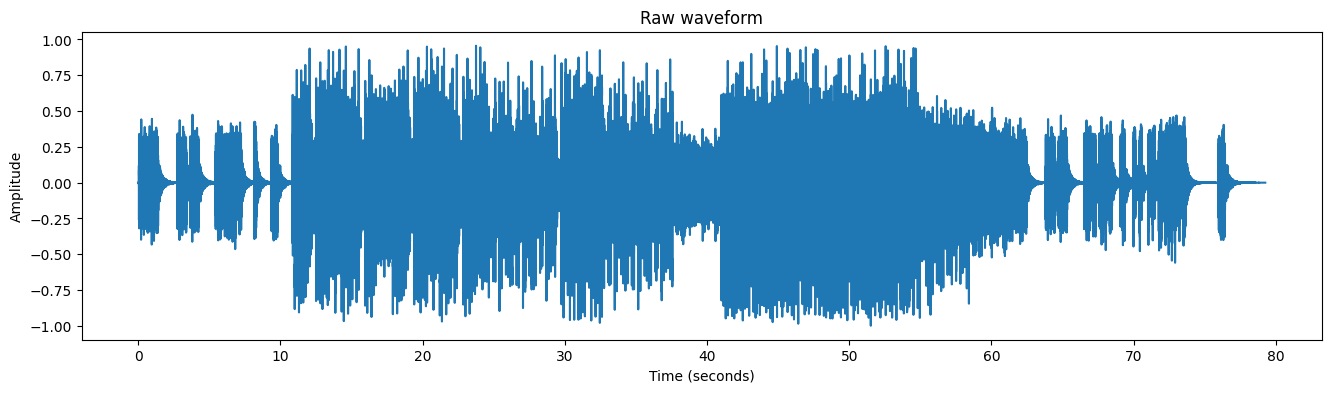

In [5]:
times = np.arange(len(audio)) / sample_rate

plt.figure(figsize=(16, 4))
plt.plot(times, audio)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Raw waveform")
plt.show()

In [ ]:
N_FFT = 2048
HOP_LENGTH = 256

stft = librosa.stft(
    audio,
    n_fft=N_FFT,
    hop_length=HOP_LENGTH,
)

magnitude = np.abs(stft)

positive_difference = np.maximum(
    magnitude[:, 1:] - magnitude[:, :-1],
    0,
)

spectral_flux = np.sum(
    positive_difference,
    axis=0,
)

spectral_flux = np.concatenate(
    [[0], spectral_flux]
)

flux_times = librosa.frames_to_time(
    np.arange(len(spectral_flux)),
    sr=sample_rate,
    hop_length=HOP_LENGTH,
)

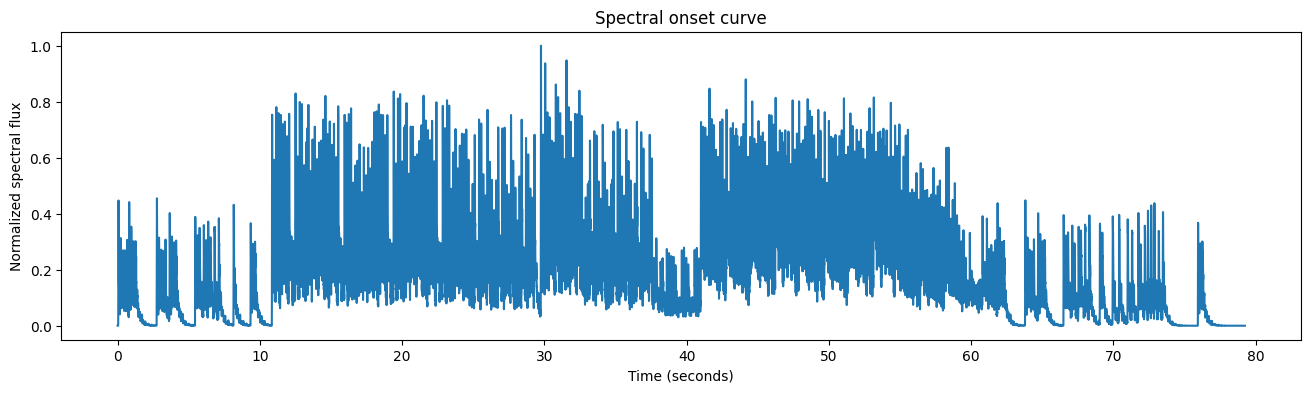

In [7]:
spectral_flux = spectral_flux / (
    np.max(spectral_flux) + 1e-9
)

plt.figure(figsize=(16, 4))
plt.plot(
    flux_times,
    spectral_flux,
)

plt.xlabel("Time (seconds)")
plt.ylabel("Normalized spectral flux")
plt.title("Spectral onset curve")
plt.show()

# Peaks, Valleys, Scoring

In [28]:
def convolution_baseline(
    data: np.ndarray,
    window_size: int = 41,
) -> np.ndarray:
    if window_size < 1 or window_size % 2 == 0:
        raise ValueError(
            "window_size must be a positive odd integer."
        )

    kernel = np.ones(window_size) / window_size
    half = window_size // 2

    padded = np.pad(
        data,
        half,
        mode="reflect",
    )

    return np.convolve(
        padded,
        kernel,
        mode="valid",
    )

def relative_score(
    data: np.ndarray,
    baseline: np.ndarray,
    epsilon: float = 1e-9,
) -> np.ndarray:
    return (
        data - baseline
    ) / (
        np.abs(baseline) + epsilon
    )

def detect_peaks(
    data: np.ndarray,
    scores: np.ndarray,
    threshold: float = 0.5,
    minimum_distance: int = 5,
) -> list[int]:
    candidates = []

    for i in range(1, len(data) - 1):
        is_local_maximum = (
            data[i] >= data[i - 1]
            and data[i] > data[i + 1]
        )

        if (
            is_local_maximum
            and scores[i] > threshold
        ):
            candidates.append(i)

    selected = []

    for index in sorted(
        candidates,
        key=lambda i: scores[i],
        reverse=True,
    ):
        if all(
            abs(index - chosen)
            >= minimum_distance
            for chosen in selected
        ):
            selected.append(index)

    return sorted(selected)

def detect_rising_onsets(
    data: np.ndarray,
    minimum_rise: float = 0.20,
    minimum_slope: float = 0.02,
    lookback: int = 30,
    minimum_distance: int = 20,
) -> tuple[list[int], dict[int, dict[str, float | int]]]:
    """
    Detect peaks supported by a preceding valley and a sufficiently
    large, sufficiently steep rise.

    Returns
    -------
    detected_peaks:
        Selected peak indices.

    features:
        Valley position, rise amount, rise time, and slope per peak.
    """
    x = np.asarray(data, dtype=float)

    candidates: list[int] = []
    features: dict[int, dict[str, float | int]] = {}

    for peak in range(1, len(x) - 1):
        is_local_peak = (
            x[peak] >= x[peak - 1]
            and x[peak] > x[peak + 1]
        )

        if not is_local_peak:
            continue

        start = max(0, peak - lookback)

        valley_relative = np.argmin(
            x[start:peak]
        )
        valley = start + int(valley_relative)

        rise = x[peak] - x[valley]
        rise_time = peak - valley
        slope = rise / max(rise_time, 1)

        if (
            rise >= minimum_rise
            and slope >= minimum_slope
        ):
            candidates.append(peak)

            features[peak] = {
                "valley": valley,
                "rise": float(rise),
                "rise_time": rise_time,
                "slope": float(slope),
            }

    # Keep the strongest candidate in each nearby region.
    selected: list[int] = []

    for peak in sorted(
        candidates,
        key=lambda p: (
            features[p]["rise"],
            features[p]["slope"],
        ),
        reverse=True,
    ):
        if all(
            abs(peak - chosen) >= minimum_distance
            for chosen in selected
        ):
            selected.append(peak)

    return sorted(selected), features

def score_grid_phase(
    peak_times: np.ndarray,
    peak_strengths: np.ndarray,
    period: float,
    phase: float,
    tolerance: float = 0.04,
) -> float:
    distances = np.abs(
        ((peak_times - phase + period / 2) % period)
        - period / 2
    )

    matches = distances <= tolerance

    timing_score = 1 - distances[matches] / tolerance

    return float(
        np.sum(
            peak_strengths[matches] * timing_score
        )
    )

def parabolic_peak_offset(values: np.ndarray, index: int) -> float:
    """
    Return the fractional offset from index to the vertex of a parabola
    fitted through values[index-1:index+2].
    """
    if index <= 0 or index >= len(values) - 1:
        return 0.0

    left = values[index - 1]
    center = values[index]
    right = values[index + 1]

    denominator = left - 2 * center + right

    if abs(denominator) < 1e-12:
        return 0.0

    return 0.5 * (left - right) / denominator

In [ ]:
baseline = convolution_baseline(
    spectral_flux,
    window_size=41,
)

scores = relative_score(
    spectral_flux,
    baseline,
)

candidate_frames = detect_peaks(
    spectral_flux,
    scores,
    threshold=0.5,
    minimum_distance=5,
)

candidate_times = flux_times[candidate_frames]

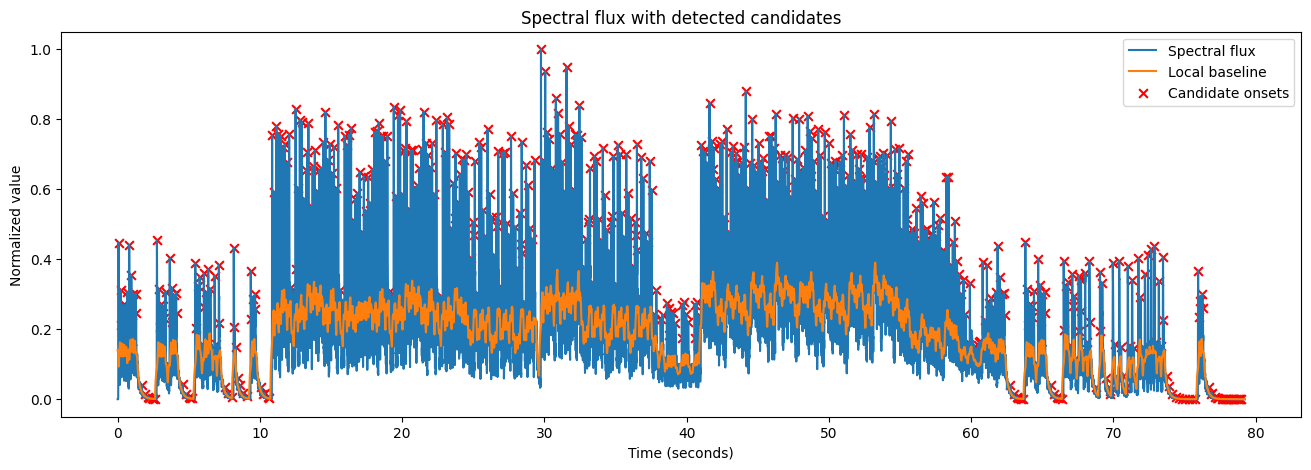

In [14]:
plt.figure(figsize=(16, 5))

plt.plot(
    flux_times,
    spectral_flux,
    label="Spectral flux",
)

plt.plot(
    flux_times,
    baseline,
    label="Local baseline",
)

plt.scatter(
    candidate_times,
    spectral_flux[candidate_frames],
    s=40,
    marker="x",
    color="red",
    label="Candidate onsets",
)

plt.xlabel("Time (seconds)")
plt.ylabel("Normalized value")
plt.title("Spectral flux with detected candidates")
plt.legend()
plt.show()

In [18]:
rise_peaks, rise_features = detect_rising_onsets(
    spectral_flux,
    minimum_rise=0.20,
    minimum_slope=0.02,
    lookback=30,
    minimum_distance=30,
)

rise_times = flux_times[rise_peaks]

print("Detected rising onsets:", len(rise_peaks))

Detected rising onsets: 175


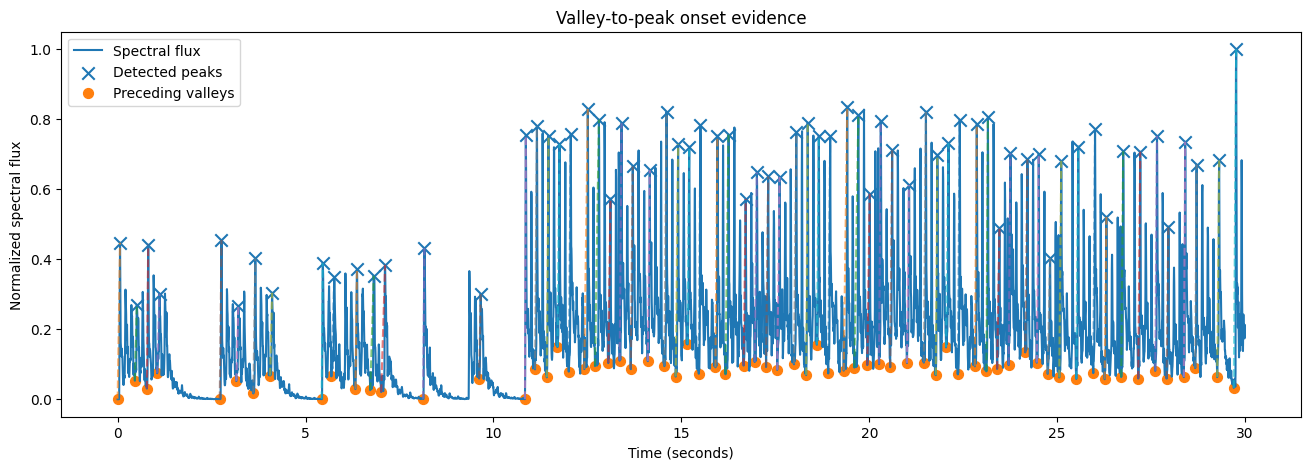

In [21]:
PLOT_START = 0
PLOT_END = 30

mask = (
    (flux_times >= PLOT_START)
    & (flux_times <= PLOT_END)
)

visible_peaks = [
    peak
    for peak in rise_peaks
    if PLOT_START <= flux_times[peak] <= PLOT_END
]

visible_valleys = [
    int(rise_features[peak]["valley"])
    for peak in visible_peaks
]

plt.figure(figsize=(16, 5))

plt.plot(
    flux_times[mask],
    spectral_flux[mask],
    label="Spectral flux",
)

plt.scatter(
    flux_times[visible_peaks],
    spectral_flux[visible_peaks],
    marker="x",
    s=80,
    label="Detected peaks",
)

plt.scatter(
    flux_times[visible_valleys],
    spectral_flux[visible_valleys],
    marker="o",
    s=50,
    label="Preceding valleys",
)

for peak, valley in zip(
    visible_peaks,
    visible_valleys,
):
    plt.plot(
        [flux_times[valley], flux_times[peak]],
        [spectral_flux[valley], spectral_flux[peak]],
        linestyle="--",
        alpha=0.6,
    )

plt.xlabel("Time (seconds)")
plt.ylabel("Normalized spectral flux")
plt.title("Valley-to-peak onset evidence")
plt.legend()
plt.show()

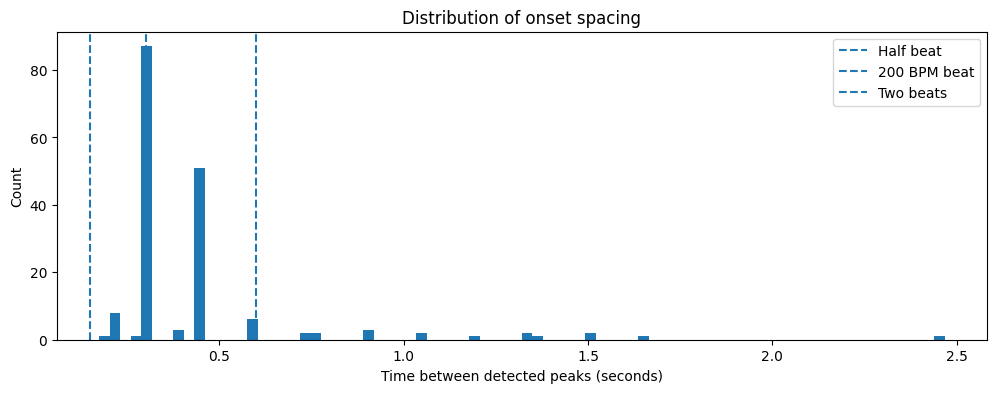

BPM: 200
Beat period: 0.3
Best phase: 0.0588
Best phase score: 49.89326035712832


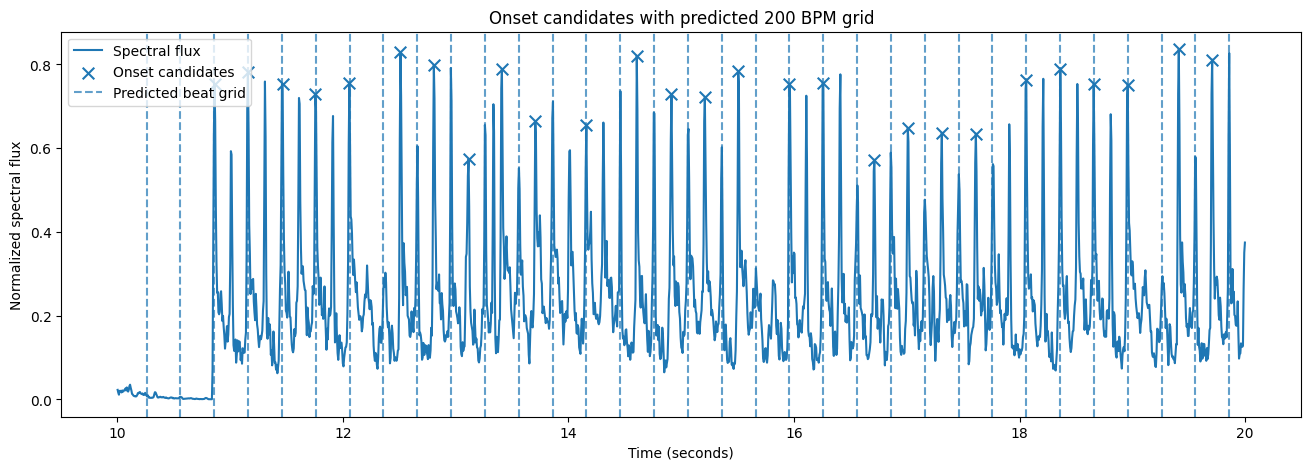

In [23]:
# Known BPM for this test song
BPM = 200
PERIOD = 60 / BPM

# Candidate peak times and strengths
peak_times = flux_times[rise_peaks]
peak_strengths = spectral_flux[rise_peaks]

# Inspect spacing between consecutive detected onsets
peak_gaps = np.diff(peak_times)

plt.figure(figsize=(12, 4))
plt.hist(peak_gaps, bins=80)
plt.axvline(0.15, linestyle="--", label="Half beat")
plt.axvline(0.30, linestyle="--", label="200 BPM beat")
plt.axvline(0.60, linestyle="--", label="Two beats")
plt.xlabel("Time between detected peaks (seconds)")
plt.ylabel("Count")
plt.title("Distribution of onset spacing")
plt.legend()
plt.show()

# Search every possible phase within one beat period
phases = np.linspace(
    0,
    PERIOD,
    500,
    endpoint=False,
)

phase_scores = np.array([
    score_grid_phase(
        peak_times=peak_times,
        peak_strengths=peak_strengths,
        period=PERIOD,
        phase=phase,
        tolerance=0.04,
    )
    for phase in phases
])

best_phase = phases[np.argmax(phase_scores)]

print("BPM:", BPM)
print("Beat period:", PERIOD)
print("Best phase:", best_phase)
print("Best phase score:", np.max(phase_scores))


# Generate the predicted beat grid
predicted_beats = np.arange(
    best_phase,
    duration,
    PERIOD,
)


# Plot a zoomed section
PLOT_START = 10
PLOT_END = 20

flux_mask = (
    (flux_times >= PLOT_START)
    & (flux_times <= PLOT_END)
)

peak_mask = (
    (peak_times >= PLOT_START)
    & (peak_times <= PLOT_END)
)

visible_beats = predicted_beats[
    (predicted_beats >= PLOT_START)
    & (predicted_beats <= PLOT_END)
]

plt.figure(figsize=(16, 5))

plt.plot(
    flux_times[flux_mask],
    spectral_flux[flux_mask],
    label="Spectral flux",
)

plt.scatter(
    peak_times[peak_mask],
    peak_strengths[peak_mask],
    marker="x",
    s=70,
    label="Onset candidates",
)

for index, beat_time in enumerate(visible_beats):
    plt.axvline(
        beat_time,
        linestyle="--",
        alpha=0.7,
        label="Predicted beat grid" if index == 0 else None,
    )

plt.xlabel("Time (seconds)")
plt.ylabel("Normalized spectral flux")
plt.title("Onset candidates with predicted 200 BPM grid")
plt.legend()
plt.show()

# Bpm Estimating 

Integer lag: 52 frames
Fractional lag: 51.69422482578343 frames
Estimated period: 0.30008438901135054 seconds
Estimated BPM: 199.9437564802164
Estimated Rounded BPM: 200

Top discrete BPM candidates:
BPM= 198.77  lag= 52  strength=232.953
BPM= 132.51  lag= 78  strength=226.478
BPM= 134.23  lag= 77  strength=226.231
BPM= 202.67  lag= 51  strength=225.986
BPM=  80.12  lag=129  strength=218.326
BPM= 100.35  lag=103  strength=217.680
BPM=  99.38  lag=104  strength=212.258
BPM=  79.51  lag=130  strength=206.433
BPM= 195.02  lag= 53  strength=204.050
BPM= 130.83  lag= 79  strength=193.434


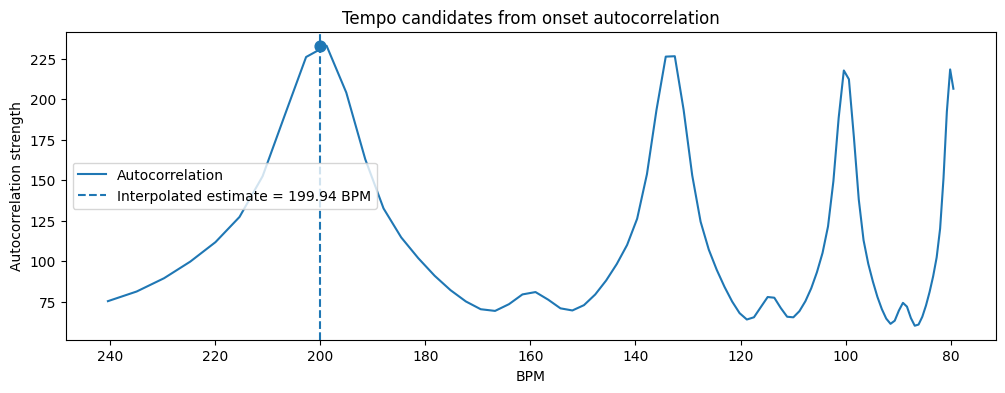

In [30]:
# Estimate BPM from the spectral-flux onset curve
# using autocorrelation + parabolic peak interpolation.

MIN_BPM = 80
MAX_BPM = 240

# Remove the mean so autocorrelation focuses on repeating variation.
onset_signal = spectral_flux - np.mean(spectral_flux)

# Keep only non-negative lags.
autocorrelation = np.correlate(
    onset_signal,
    onset_signal,
    mode="full",
)

autocorrelation = autocorrelation[
    len(autocorrelation) // 2:
]

frames_per_second = sample_rate / HOP_LENGTH

# Convert BPM limits into autocorrelation-lag limits.
minimum_lag = int(
    np.floor(
        frames_per_second * 60 / MAX_BPM
    )
)

maximum_lag = int(
    np.ceil(
        frames_per_second * 60 / MIN_BPM
    )
)

lags = np.arange(
    minimum_lag,
    maximum_lag + 1,
)

search_region = autocorrelation[
    minimum_lag:maximum_lag + 1
]


# Find the strongest integer-lag candidate.
best_local_index = int(
    np.argmax(search_region)
)

best_integer_lag = int(
    lags[best_local_index]
)


# Refine the winning lag using a parabola through
# the winning bin and its two neighbors.
fractional_offset = parabolic_peak_offset(
    search_region,
    best_local_index,
)

best_fractional_lag = (
    best_integer_lag
    + fractional_offset
)

estimated_period = (
    best_fractional_lag
    / frames_per_second
)

estimated_bpm = (
    60
    / estimated_period
)


print(
    "Integer lag:",
    best_integer_lag,
    "frames",
)

print(
    "Fractional lag:",
    best_fractional_lag,
    "frames",
)

print(
    "Estimated period:",
    estimated_period,
    "seconds",
)

print(
    "Estimated BPM:",
    estimated_bpm,
)

print(
    "Estimated Rounded BPM:",
    round(estimated_bpm),
)

# Print the strongest discrete autocorrelation candidates.
top_indices = np.argsort(
    search_region
)[-10:][::-1]

print("\nTop discrete BPM candidates:")

for local_index in top_indices:
    lag = lags[local_index]
    bpm = 60 * frames_per_second / lag
    strength = search_region[local_index]

    print(
        f"BPM={bpm:7.2f}  "
        f"lag={lag:3d}  "
        f"strength={strength:.3f}"
    )


# Convert every integer lag to BPM for plotting.
candidate_bpms = (
    60
    * frames_per_second
    / lags
)

plt.figure(figsize=(12, 4))

plt.plot(
    candidate_bpms,
    search_region,
    label="Autocorrelation",
)

plt.axvline(
    estimated_bpm,
    linestyle="--",
    label=(
        f"Interpolated estimate "
        f"= {estimated_bpm:.2f} BPM"
    ),
)

plt.scatter(
    [estimated_bpm],
    [
        search_region[best_local_index]
    ],
    s=60,
    zorder=4,
)

plt.xlabel("BPM")
plt.ylabel("Autocorrelation strength")
plt.title(
    "Tempo candidates from onset autocorrelation"
)
plt.legend()

# Larger lag means smaller BPM, so the array runs backward.
plt.gca().invert_xaxis()

plt.show()

Estimated BPM: 200
Estimated period: 0.3
Best phase: 0.058949999999999995 seconds
Number of predicted beats: 264


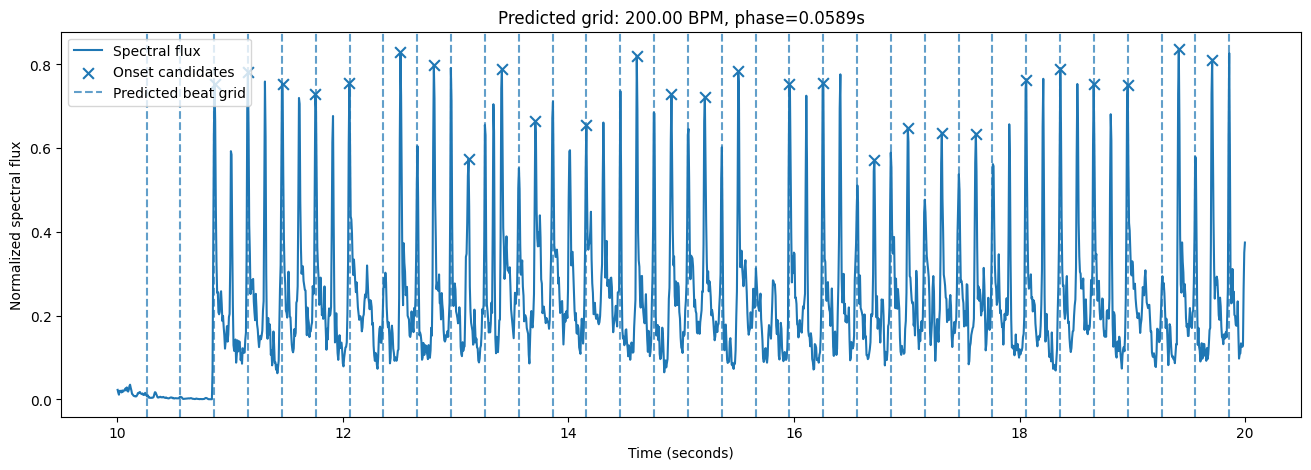

In [34]:
# Estimate the best beat-grid phase from the detected onset peaks.
estimated_bpm = round(estimated_bpm)
PERIOD = 60 / estimated_bpm

peak_times = flux_times[rise_peaks]
peak_strengths = spectral_flux[rise_peaks]

PHASE_STEPS = 2000
MATCH_TOLERANCE = 0.04  # 40 ms

phases = np.linspace(
    0,
    PERIOD,
    PHASE_STEPS,
    endpoint=False,
)

phase_scores = np.zeros_like(phases)

for i, phase in enumerate(phases):
    distances = np.abs(
        ((peak_times - phase + PERIOD / 2) % PERIOD)
        - PERIOD / 2
    )

    matches = distances <= MATCH_TOLERANCE

    if np.any(matches):
        timing_weight = (
            1 - distances[matches] / MATCH_TOLERANCE
        )

        phase_scores[i] = np.sum(
            peak_strengths[matches] * timing_weight
        )

best_phase = phases[np.argmax(phase_scores)]

predicted_beats = np.arange(
    best_phase,
    duration,
    PERIOD,
)

print("Estimated BPM:", estimated_bpm)
print("Estimated period:", PERIOD)
print("Best phase:", best_phase, "seconds")
print("Number of predicted beats:", len(predicted_beats))

PLOT_START = 10
PLOT_END = 20

flux_mask = (
    (flux_times >= PLOT_START)
    & (flux_times <= PLOT_END)
)

peak_mask = (
    (peak_times >= PLOT_START)
    & (peak_times <= PLOT_END)
)

visible_beats = predicted_beats[
    (predicted_beats >= PLOT_START)
    & (predicted_beats <= PLOT_END)
]

plt.figure(figsize=(16, 5))

plt.plot(
    flux_times[flux_mask],
    spectral_flux[flux_mask],
    label="Spectral flux",
)

plt.scatter(
    peak_times[peak_mask],
    peak_strengths[peak_mask],
    marker="x",
    s=60,
    label="Onset candidates",
)

for i, beat_time in enumerate(visible_beats):
    plt.axvline(
        beat_time,
        linestyle="--",
        alpha=0.7,
        label="Predicted beat grid" if i == 0 else None,
    )

plt.xlabel("Time (seconds)")
plt.ylabel("Normalized spectral flux")
plt.title(
    f"Predicted grid: {estimated_bpm:.2f} BPM, "
    f"phase={best_phase:.4f}s"
)
plt.legend()
plt.show()

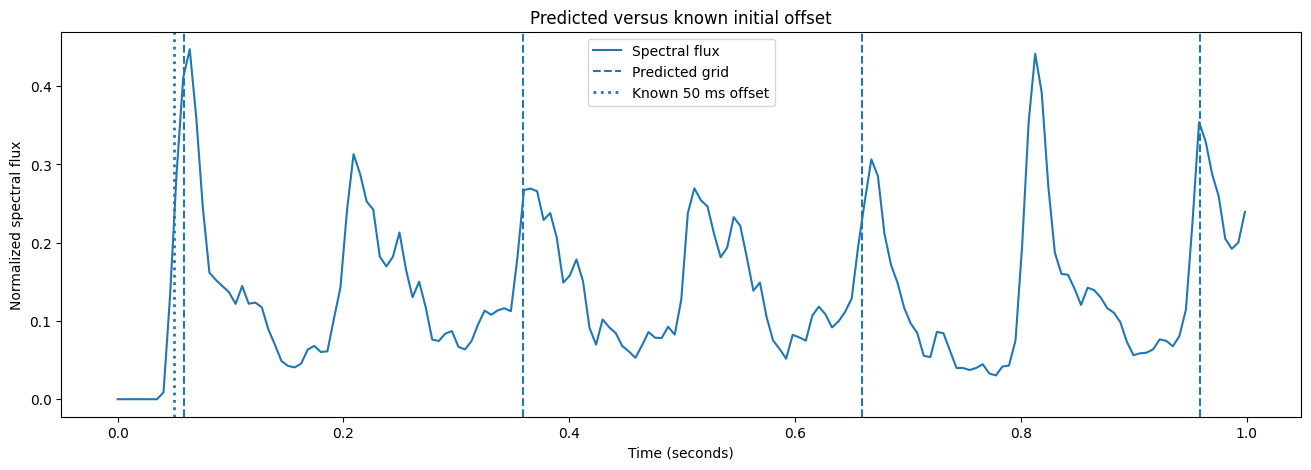

In [35]:
PLOT_START = 0
PLOT_END = 1

flux_mask = (
    (flux_times >= PLOT_START)
    & (flux_times <= PLOT_END)
)

visible_beats = predicted_beats[
    (predicted_beats >= PLOT_START)
    & (predicted_beats <= PLOT_END)
]

plt.figure(figsize=(16, 5))

plt.plot(
    flux_times[flux_mask],
    spectral_flux[flux_mask],
    label="Spectral flux",
)

for i, beat_time in enumerate(visible_beats):
    plt.axvline(
        beat_time,
        linestyle="--",
        label="Predicted grid" if i == 0 else None,
    )

plt.axvline(
    0.050,
    linestyle=":",
    linewidth=2,
    label="Known 50 ms offset",
)

plt.xlabel("Time (seconds)")
plt.ylabel("Normalized spectral flux")
plt.title("Predicted versus known initial offset")
plt.legend()
plt.show()

# Segmentation Tool

In [83]:
import numpy as np

def refine_onset_times(
    spectral_flux: np.ndarray,
    flux_times: np.ndarray,
    rise_peaks: list[int],
    rise_features: dict[int, dict[str, float | int]],
    crossing_fraction: float = 0.2,
) -> np.ndarray:
    """
    Move each onset estimate from the flux maximum back to the
    first threshold crossing on its rising edge.
    """
    refined_times = []

    for peak in rise_peaks:
        valley = int(rise_features[peak]["valley"])

        valley_value = spectral_flux[valley]
        peak_value = spectral_flux[peak]

        crossing_level = (
            valley_value
            + crossing_fraction
            * (peak_value - valley_value)
        )

        crossing_index = peak

        for index in range(valley, peak + 1):
            if spectral_flux[index] >= crossing_level:
                crossing_index = index
                break

        refined_times.append(
            flux_times[crossing_index]
        )

    return np.asarray(refined_times)

In [82]:
def fit_linear_grid(
    beat_indices: np.ndarray,
    beat_times: np.ndarray,
    start: int,
    end: int,
    integer_bpm: bool = False,
) -> tuple[float, float, np.ndarray]:
    """
    Fit:

        time = offset + period * beat_index

    If integer_bpm=True, round the fitted BPM to the nearest integer
    and refit only the offset using that fixed integer BPM.
    """
    indices = beat_indices[start:end + 1].astype(float)
    times = beat_times[start:end + 1].astype(float)

    if len(indices) < 2:
        raise ValueError(
            "At least two observations are required to estimate BPM."
        )

    if np.ptp(indices) == 0:
        raise ValueError(
            "Beat indices must contain at least two distinct values."
        )

    design = np.column_stack([
        np.ones_like(indices),
        indices,
    ])

    offset, period = np.linalg.lstsq(
        design,
        times,
        rcond=None,
    )[0]

    if (
        not np.isfinite(period)
        or period <= 0
    ):
        raise ValueError(
            "The fitted period is invalid."
        )

    if integer_bpm:
        fitted_bpm = 60 / period

        if (
            not np.isfinite(fitted_bpm)
            or fitted_bpm <= 0
        ):
            raise ValueError(
                "The fitted BPM is invalid."
            )

        rounded_bpm = int(round(fitted_bpm))

        if rounded_bpm <= 0:
            raise ValueError(
                "Rounded BPM must be positive."
            )

        period = 60 / rounded_bpm

        # Best offset with the integer period fixed.
        offset = np.mean(
            times - period * indices
        )

    predicted = offset + period * indices
    residuals = times - predicted

    return offset, period, residuals

In [94]:
def minimum_timing_sections(
    beat_indices: np.ndarray,
    beat_times: np.ndarray,
    tolerance_seconds: float = 0.010,
    minimum_section_points: int = 4,
    error_quantile: float = 0.95,
    integer_bpm: bool = False,
) -> list[dict]:
    beat_indices = np.asarray(beat_indices, dtype=int)
    beat_times = np.asarray(beat_times, dtype=float)

    if beat_indices.shape != beat_times.shape:
        raise ValueError(
            "beat_indices and beat_times must have the same shape."
        )

    if not 0 < error_quantile <= 1:
        raise ValueError(
            "error_quantile must be between 0 and 1."
        )

    if minimum_section_points < 2:
        raise ValueError(
            "minimum_section_points must be at least 2."
        )

    n = len(beat_times)

    if n == 0:
        return []

    if n < minimum_section_points:
        raise ValueError(
            "Not enough matched beats for one timing section."
        )

    infinity = n + 1

    best_count = np.full(
        n + 1,
        infinity,
        dtype=int,
    )

    best_error = np.full(
        n + 1,
        np.inf,
        dtype=float,
    )

    best_error[0] = 0.0

    previous = np.full(
        n + 1,
        -1,
        dtype=int,
    )

    best_count[0] = 0

    segment_cache = {}

    for end_exclusive in range(1, n + 1):
        for start in range(end_exclusive):
            length = end_exclusive - start

            # Require the requested minimum number of matched points
            # for every section, including the first and final ones.
            if length < minimum_section_points:
                continue

            # No valid path reaches this start position.
            if best_count[start] == infinity:
                continue

            try:
                offset, period, residuals = fit_linear_grid(
                    beat_indices=beat_indices,
                    beat_times=beat_times,
                    start=start,
                    end=end_exclusive - 1,
                    integer_bpm=integer_bpm,
                )
            except ValueError:
                continue

            if (
                not np.isfinite(offset)
                or not np.isfinite(period)
                or period <= 0
                or not np.all(np.isfinite(residuals))
            ):
                continue

            absolute_errors = np.abs(residuals)

            representative_error = float(
                np.quantile(
                    absolute_errors,
                    error_quantile,
                )
            )

            max_error = float(
                np.max(absolute_errors)
            )

            if (
                not np.isfinite(representative_error)
                or not np.isfinite(max_error)
            ):
                continue

            segment_cache[(start, end_exclusive)] = {
                "offset": float(offset),
                "period": float(period),
                "representative_error": representative_error,
                "max_error": max_error,
            }

            if representative_error > tolerance_seconds:
                continue

            candidate_count = best_count[start] + 1

            # Use mean squared residual as the secondary cost.
            segment_error = float(
                np.sum(residuals ** 2)
            )

            candidate_error = (
                best_error[start]
                + segment_error
            )

            better_section_count = (
                candidate_count
                < best_count[end_exclusive]
            )

            same_count_better_fit = (
                candidate_count
                == best_count[end_exclusive]
                and candidate_error
                < best_error[end_exclusive]
            )

            if better_section_count or same_count_better_fit:
                best_count[end_exclusive] = candidate_count
                best_error[end_exclusive] = candidate_error
                previous[end_exclusive] = start

    if previous[n] == -1:
        raise ValueError(
            "No valid segmentation found. "
            "Increase the tolerance, reduce minimum_section_points, "
            "or inspect the matched onset times."
        )

    sections = []
    end_exclusive = n

    while end_exclusive > 0:
        start = previous[end_exclusive]

        if start < 0:
            raise RuntimeError(
                "Segmentation backtracking failed."
            )

        cached = segment_cache[(start, end_exclusive)]

        offset = cached["offset"]
        period = cached["period"]
        representative_error = cached["representative_error"]
        max_error = cached["max_error"]

        if representative_error > tolerance_seconds + 1e-12:
            raise RuntimeError(
                "Internal error: returned section exceeds tolerance. "
                f"Section error={representative_error * 1000:.3f} ms, "
                f"tolerance={tolerance_seconds * 1000:.3f} ms."
            )

        bpm_value = 60 / period

        if integer_bpm:
            bpm_value = int(round(bpm_value))
        else:
            bpm_value = float(bpm_value)

        sections.append({
            "start_observation": start,
            "end_observation": end_exclusive - 1,

            "start_beat_index": int(
                beat_indices[start]
            ),

            "end_beat_index": int(
                beat_indices[end_exclusive - 1]
            ),

            "start_time": float(
                beat_times[start]
            ),

            "end_time": float(
                beat_times[end_exclusive - 1]
            ),

            "offset": float(offset),
            "period": float(period),
            "bpm": bpm_value,

            "quantile_error_ms": (
                representative_error * 1000
            ),

            "max_error_ms": (
                max_error * 1000
            ),

            "number_of_points": (
                end_exclusive - start
            ),
        })

        end_exclusive = start

    return list(reversed(sections))

In [84]:
peak_times = flux_times[rise_peaks]
peak_strengths = spectral_flux[rise_peaks]

MATCH_TOLERANCE = 0.06

matched_beat_indices = []
matched_grid_times = []
matched_peak_times = []
timing_errors = []

for beat_index, grid_time in enumerate(predicted_beats):
    nearest_index = np.argmin(
        np.abs(peak_times - grid_time)
    )

    nearest_peak = peak_times[nearest_index]
    error = nearest_peak - grid_time

    if abs(error) <= MATCH_TOLERANCE:
        matched_beat_indices.append(beat_index)
        matched_grid_times.append(grid_time)
        matched_peak_times.append(nearest_peak)
        timing_errors.append(error)

matched_beat_indices = np.asarray(
    matched_beat_indices,
    dtype=int,
)

matched_peak_times = np.asarray(
    matched_peak_times,
    dtype=float,
)

timing_errors = np.asarray(
    timing_errors,
    dtype=float,
)

# tolerance test

In [89]:
starting_tol = 15
USE_INTEGER_BPM = True

for tolerance_ms in range(starting_tol, 0, -1):
    try:
        sections = minimum_timing_sections(
            beat_indices=test_beat_indices,
            beat_times=test_beat_times,
            tolerance_seconds=0.005,
            minimum_section_points=8,
            error_quantile=1.0,
            integer_bpm=True,
        )

        print(
            f"\nTolerance {tolerance_ms:2d} ms: "
            f"{len(sections)} section(s)"
        )

        for section_number, section in enumerate(sections, start=1):
            start = section["start_observation"]
            end = section["end_observation"]

            offset, period, residuals = fit_linear_grid(
                beat_indices=matched_beat_indices,
                beat_times=matched_peak_times,
                start=start,
                end=end,
                integer_bpm=USE_INTEGER_BPM,
            )

            absolute_errors_ms = np.abs(residuals) * 1000

            print(
                f"  Section {section_number}: "
                f"beats {section['start_beat_index']}–"
                f"{section['end_beat_index']}, "
                f"BPM={section['bpm']}"
            )

            print(
                f"    median error: "
                f"{np.median(absolute_errors_ms):.3f} ms"
            )

            print(
                f"    95th percentile: "
                f"{np.percentile(absolute_errors_ms, 95):.3f} ms"
            )

            print(
                f"    maximum error: "
                f"{np.max(absolute_errors_ms):.3f} ms"
            )

    except ValueError:
        print(
            f"\nTolerance {tolerance_ms:2d} ms: "
            "no valid segmentation"
        )
        break


Tolerance 15 ms: 1 section(s)
  Section 1: beats 0–199, BPM=200
    median error: 1.958 ms
    95th percentile: 5.991 ms
    maximum error: 23.439 ms

Tolerance 14 ms: 1 section(s)
  Section 1: beats 0–199, BPM=200
    median error: 1.958 ms
    95th percentile: 5.991 ms
    maximum error: 23.439 ms

Tolerance 13 ms: 1 section(s)
  Section 1: beats 0–199, BPM=200
    median error: 1.958 ms
    95th percentile: 5.991 ms
    maximum error: 23.439 ms

Tolerance 12 ms: 1 section(s)
  Section 1: beats 0–199, BPM=200
    median error: 1.958 ms
    95th percentile: 5.991 ms
    maximum error: 23.439 ms

Tolerance 11 ms: 1 section(s)
  Section 1: beats 0–199, BPM=200
    median error: 1.958 ms
    95th percentile: 5.991 ms
    maximum error: 23.439 ms

Tolerance 10 ms: 1 section(s)
  Section 1: beats 0–199, BPM=200
    median error: 1.958 ms
    95th percentile: 5.991 ms
    maximum error: 23.439 ms

Tolerance  9 ms: 1 section(s)
  Section 1: beats 0–199, BPM=200
    median error: 1.958 ms
  

# synthetic test

test 1: bpm change

In [90]:
# Synthetic test:
# beats 0–99 at 200 BPM
# beats 100–199 at 198 BPM

change_index = 100

test_beat_indices = np.arange(200, dtype=int)
test_beat_times = np.empty(200, dtype=float)

period_1 = 60 / 200
period_2 = 60 / 198

offset_1 = 0.050

test_beat_times[:change_index] = (
    offset_1
    + test_beat_indices[:change_index] * period_1
)

change_time = (
    test_beat_times[change_index - 1]
    + period_2
)

test_beat_times[change_index:] = (
    change_time
    + (
        test_beat_indices[change_index:]
        - change_index
    ) * period_2
)

sections = minimum_timing_sections(
    beat_indices=test_beat_indices,
    beat_times=test_beat_times,
    tolerance_seconds=0.005,
    minimum_section_points=8,
    error_quantile=0.95,
    integer_bpm=True,
)

for section in sections:
    print(section)

{'start_observation': 0, 'end_observation': 98, 'start_beat_index': 0, 'end_beat_index': 98, 'start_time': 0.05, 'end_time': 29.45, 'offset': 0.05000000000000049, 'period': 0.3, 'bpm': 200, 'quantile_error_ms': 8.881784197001252e-13, 'max_error_ms': 8.881784197001252e-13, 'number_of_points': 99}
{'start_observation': 99, 'end_observation': 199, 'start_beat_index': 99, 'end_beat_index': 199, 'start_time': 29.75, 'end_time': 60.053030303030305, 'offset': -0.24999999999999947, 'period': 0.30303030303030304, 'bpm': 198, 'quantile_error_ms': 7.105427357601002e-12, 'max_error_ms': 7.105427357601002e-12, 'number_of_points': 101}


test2: offset change

In [91]:
# Same BPM throughout, but shift the grid by 3 ms after beat 100.

test_beat_indices = np.arange(200, dtype=int)
test_beat_times = (
    0.050
    + test_beat_indices * (60 / 200)
)

test_beat_times[100:] += 0.003

sections = minimum_timing_sections(
    beat_indices=test_beat_indices,
    beat_times=test_beat_times,
    tolerance_seconds=0.002,
    minimum_section_points=8,
    error_quantile=0.95,
    integer_bpm=True,
)

for section in sections:
    print(section)

{'start_observation': 0, 'end_observation': 199, 'start_beat_index': 0, 'end_beat_index': 199, 'start_time': 0.05, 'end_time': 59.75299999999999, 'offset': 0.05149999999999901, 'period': 0.3, 'bpm': 200, 'quantile_error_ms': 1.5000000000000568, 'max_error_ms': 1.5000000000000568, 'number_of_points': 200}


# erm

In [95]:
USE_INTEGER_BPM = True
SECTION_TOLERANCE_MS = 6

sections = minimum_timing_sections(
    beat_indices=matched_beat_indices,
    beat_times=matched_peak_times,
    tolerance_seconds=SECTION_TOLERANCE_MS / 1000,
    minimum_section_points=8,
    error_quantile=0.95,
    integer_bpm=USE_INTEGER_BPM,
)

for i, section in enumerate(sections, start=1):
    print(
        f"Section {i}: "
        f"beats {section['start_beat_index']}–"
        f"{section['end_beat_index']}, "
        f"BPM={section['bpm']}, "
        f"offset={section['offset']:.6f}s, "
        f"95% error={section['quantile_error_ms']:.3f}ms"
    )

Section 1: beats 0–254, BPM=200, offset=0.059645s, 95% error=5.991ms


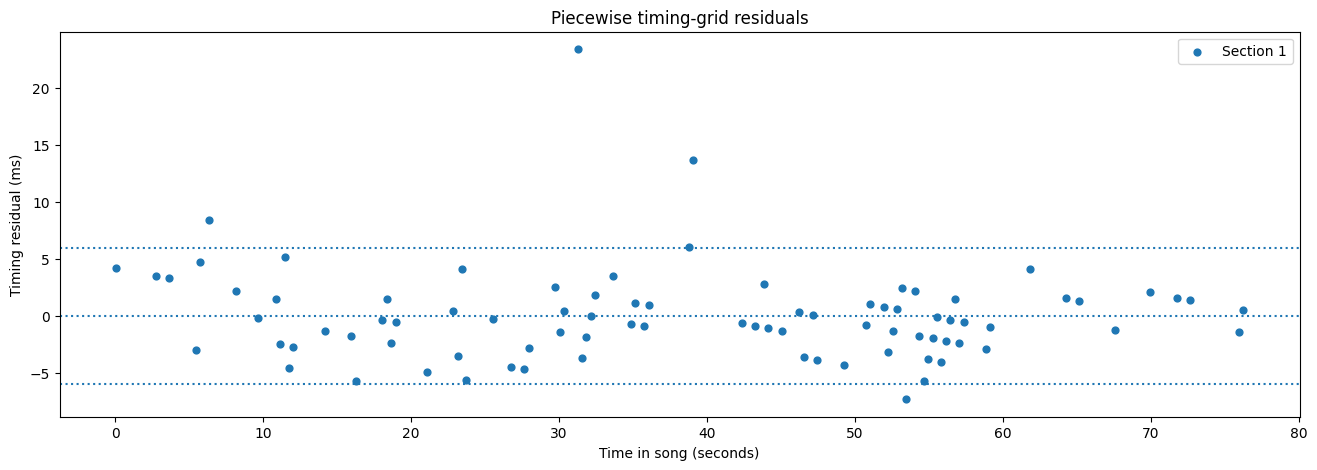

In [96]:
plt.figure(figsize=(16, 5))

for section_number, section in enumerate(sections, start=1):
    start = section["start_observation"]
    end = section["end_observation"]

    section_indices = matched_beat_indices[start:end + 1]
    section_times = matched_peak_times[start:end + 1]

    predicted_times = (
        section["offset"]
        + section["period"] * section_indices
    )

    residuals_ms = (
        section_times - predicted_times
    ) * 1000

    plt.scatter(
        section_times,
        residuals_ms,
        s=24,
        label=f"Section {section_number}",
    )

    if section_number > 1:
        plt.axvline(
            section["start_time"],
            linestyle="--",
        )

plt.axhline(0, linestyle=":")
plt.axhline(
    SECTION_TOLERANCE_MS,
    linestyle=":",
)
plt.axhline(
    -SECTION_TOLERANCE_MS,
    linestyle=":",
)

plt.xlabel("Time in song (seconds)")
plt.ylabel("Timing residual (ms)")
plt.title("Piecewise timing-grid residuals")
plt.legend()
plt.show()